In [1]:
"""LangGraph Pipeline & HITL StateGraph Wiring for QuoteFlow AI.

Topology:
START -> multimodal_extractor_node 
      -> inventory_and_billing_analyzer_node 
      -> revenue_and_procurement_node 
      -> hitl_gate_node [HITL Interrupt Gate]
         |-- (human_decision == 'refine')  --> natural_language_refinement_node 
         |                                     |--> (loops back to inventory_and_billing_analyzer_node)
         |-- (human_decision == 'approve') --> execute_dispatch_node -> END
"""

from typing import Literal
from langgraph.graph import StateGraph, START, END
from agent.state import QuoteFlowState
from agent.nodes import (
    multimodal_extractor_node,
    inventory_and_billing_analyzer_node,
    revenue_and_procurement_node,
    hitl_gate_node,
    natural_language_refinement_node,
    execute_dispatch_node,
)
from agent.checkpointer import get_postgres_checkpointer

def route_hitl_decision(state: QuoteFlowState) -> Literal["execute_dispatch_node", "refinement_node"]:
    """Conditional edge from hitl_gate_node:
    If human requested natural language refinement, route to refinement_node.
    Otherwise (approval / default), route to execute_dispatch_node.
    """
    decision = state.get("human_decision")
    feedback = state.get("human_edit_feedback") or state.get("refinement_instruction")
    if decision == "refine" or (feedback and decision != "approve"):
        return "refinement_node"
    return "execute_dispatch_node"

def create_quoteflow_graph(checkpointer=None):
    """Constructs and compiles the QuoteFlow AI StateGraph with Natural Language Refinement Loop.
    
    Uses `interrupt_before=['hitl_gate_node']` to pause execution,
    persisting state in Neon PostgreSQL via PostgresSaver for human vendor review.
    """
    builder = StateGraph(QuoteFlowState)

    # 1. Add Core & Refinement Nodes
    builder.add_node("multimodal_extractor_node", multimodal_extractor_node)
    builder.add_node("inventory_and_billing_analyzer_node", inventory_and_billing_analyzer_node)
    builder.add_node("revenue_and_procurement_node", revenue_and_procurement_node)
    builder.add_node("hitl_gate_node", hitl_gate_node)
    builder.add_node("refinement_node", natural_language_refinement_node)
    builder.add_node("execute_dispatch_node", execute_dispatch_node)

    # 2. Wire Linear Edges
    builder.add_edge(START, "multimodal_extractor_node")
    builder.add_edge("multimodal_extractor_node", "inventory_and_billing_analyzer_node")
    builder.add_edge("inventory_and_billing_analyzer_node", "revenue_and_procurement_node")
    builder.add_edge("revenue_and_procurement_node", "hitl_gate_node")

    # 3. Wire Conditional Branching from HITL Gate
    builder.add_conditional_edges(
        "hitl_gate_node",
        route_hitl_decision,
        {
            "execute_dispatch_node": "execute_dispatch_node",
            "refinement_node": "refinement_node",
        }
    )

    # 4. Loop back from refinement_node to Node 2 (re-evaluate 3-Tier inventory & GST math)
    builder.add_edge("refinement_node", "inventory_and_billing_analyzer_node")
    builder.add_edge("execute_dispatch_node", END)

    # 5. Checkpointer configuration:
    # If a checkpointer is passed (standalone execution), use it.
    # If None (LangGraph API / `langgraph dev`), compile without it so the platform handles persistence automatically.
    compile_kwargs = {"interrupt_before": ["hitl_gate_node"]}
    if checkpointer is not None:
        compile_kwargs["checkpointer"] = checkpointer

    # 6. Compile with Human-In-The-Loop Interrupt Gate
    graph = builder.compile(**compile_kwargs)
    return graph

# Default graph instance for LangGraph API / `langgraph dev` (persistence handled by platform)
graph = create_quoteflow_graph()

# # Run this once at the bottom of app/agent/graph.py
# png_bytes = graph.get_graph().draw_mermaid_png()
# with open("quoteflow_architecture.png", "wb") as f:
#     f.write(png_bytes)
# print("✅ Saved quoteflow_architecture.png!")


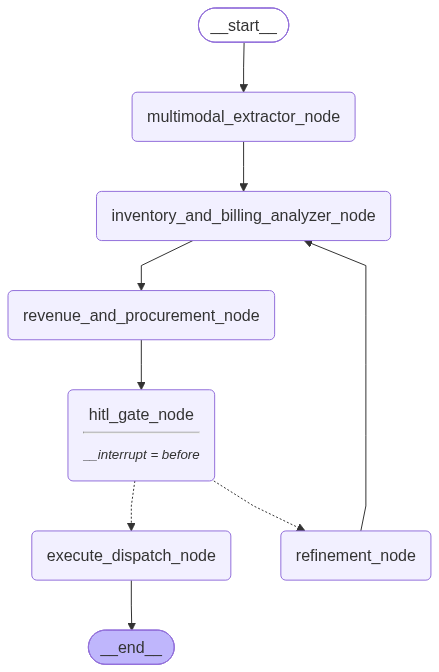

In [2]:
graph